In [1]:
# =====================================
# CNN1D FULLY SEGMENT EXPERIMENT
# =====================================

import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.run.model.run_segment_mamba_classifier import RunSegmentMamba
from src.run.preprocess.config import _project_path


=== Running experiment with window_size=128 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=1.0274 | train_accuracy=0.4833 | train_f1=0.3922 | train_auc=0.5350 | train_precision=0.4545 | train_recall=0.3448 | train_specificity=0.6129 | val_loss=0.8296 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.7188 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=0.7332 | train_accuracy=0.5667 | train_f1=0.5517 | train_auc=0.5439 | train_precision=0.5517 | train_recall=0.5517 | train_specificity=0.5806 | val_loss=0.8011 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.6071 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.7773 | train_accuracy=0.4833 | train_f1=0.6517 | train_auc=0.6830 | train_precision=0.4833 | train_recall=1.0000 | train_specificity=0.0000 | val_loss=0.6733 | val_accu

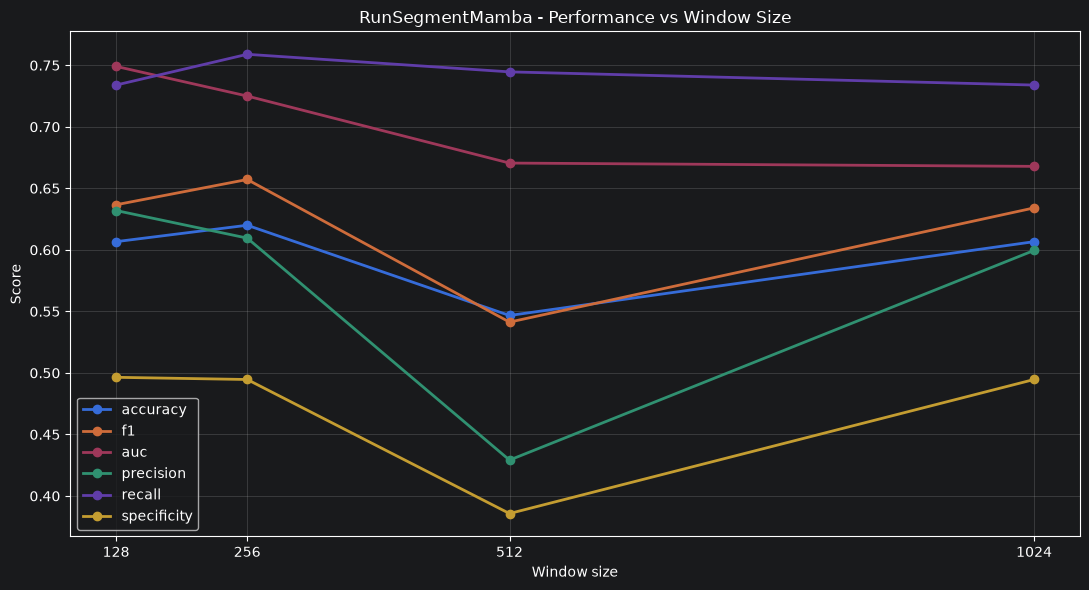


=== BEST WINDOW SIZE ===
Window size: 256
Accuracy: 0.6200
F1: 0.6572
AUC: 0.7250


In [2]:
# WINDOW SIZE - RunSegmentMamba

results = []

window_sizes = [128, 256, 512, 1024]

for w in window_sizes:

    print(f"\n=== Running experiment with window_size={w} ===")

    runner = RunSegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed","pressure_derivative"),

        window_size=w,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=50,
        batch_size=32,
        learning_rate=1e-3,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val no)/window_size/w_{w}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "window_size": w,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("window_size")

print("\n=== WINDOW SIZE SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "segment_mamba_window_size_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["window_size"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(df["window_size"])

plt.xlabel("Window size")
plt.ylabel("Score")
plt.title("RunSegmentMamba - Performance vs Window Size")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST WINDOW SIZE ===")
print(f"Window size: {int(best['window_size'])}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")


=== Running experiment with epoch=25 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=1.0777 | train_accuracy=0.5167 | train_f1=0.4727 | train_auc=0.5139 | train_precision=0.5000 | train_recall=0.4483 | train_specificity=0.5806 | val_loss=0.8517 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.7009 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=0.7233 | train_accuracy=0.5167 | train_f1=0.4727 | train_auc=0.5640 | train_precision=0.5000 | train_recall=0.4483 | train_specificity=0.5806 | val_loss=0.8271 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.6429 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.7801 | train_accuracy=0.5000 | train_f1=0.6591 | train_auc=0.7030 | train_precision=0.4915 | train_recall=1.0000 | train_specificity=0.0323 | val_loss=0.7113 | val_accuracy=0.

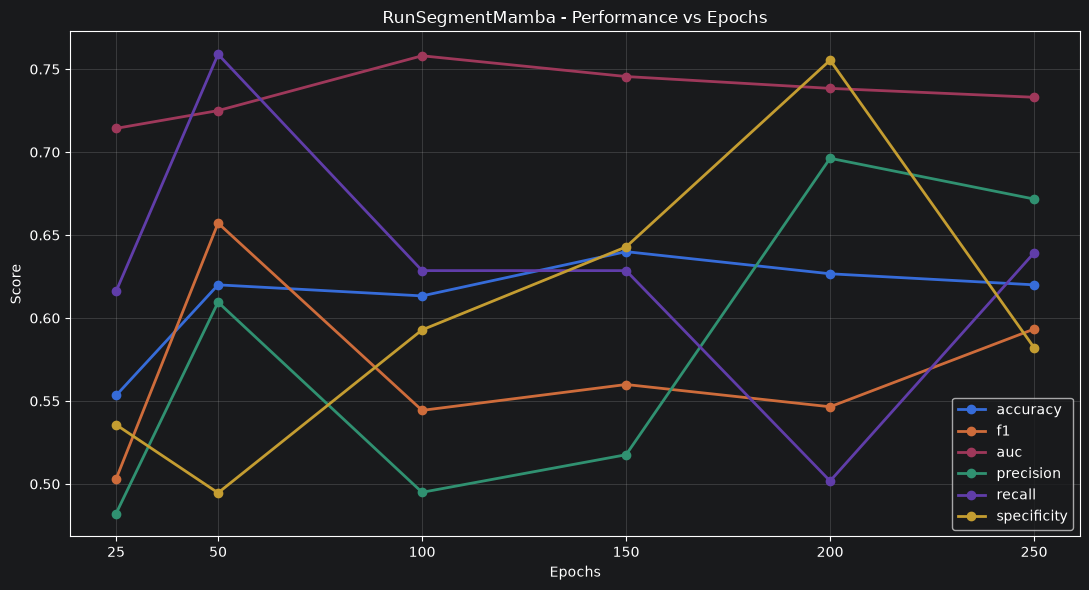


=== BEST EPOCH ===
Epochs: 150
Accuracy: 0.6400
F1: 0.5599
AUC: 0.7455


In [3]:
# EPOCHS - RunSegmentMamba
import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

epochs = [25, 50, 100, 150, 200, 250]

for e in epochs:

    print(f"\n=== Running experiment with epoch={e} ===")

    runner = RunSegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative",),

        window_size=256,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=e,
        batch_size=32,
        learning_rate=1e-3,
        regularization=1e-6,
        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val no)/epochs/e_{e}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "epoch": e,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("epoch")

print("\n=== EPOCHS SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "segment_mamba_epochs_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["epoch"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(df["epoch"])

plt.xlabel("Epochs")
plt.ylabel("Score")
plt.title("RunSegmentMamba - Performance vs Epochs")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST EPOCH ===")
print(f"Epochs: {int(best['epoch'])}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")


=== Running experiment with learning_rate=0.01 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=1.8299 | train_accuracy=0.5167 | train_f1=0.4727 | train_auc=0.5061 | train_precision=0.5000 | train_recall=0.4483 | train_specificity=0.5806 | val_loss=0.8201 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.5312 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=1.3964 | train_accuracy=0.5167 | train_f1=0.4912 | train_auc=0.5417 | train_precision=0.5000 | train_recall=0.4828 | train_specificity=0.5484 | val_loss=1.4483 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.5670 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=1.0632 | train_accuracy=0.4833 | train_f1=0.6517 | train_auc=0.7052 | train_precision=0.4833 | train_recall=1.0000 | train_specificity=0.0000 | val_loss=0.6944 | val_a

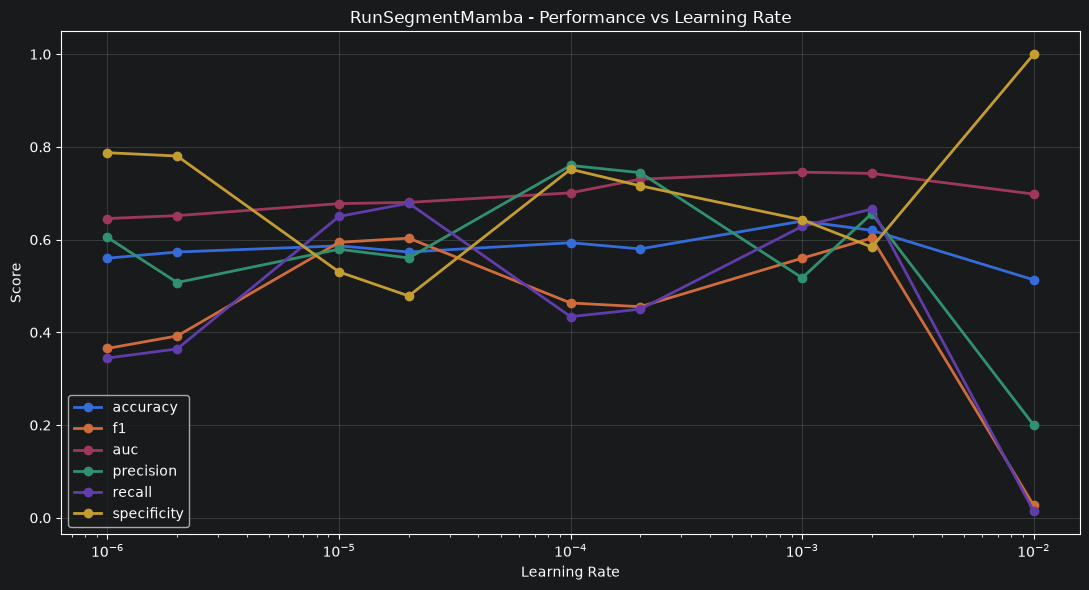


=== BEST LEARNING RATE ===
Learning Rate: 1.0e-03
Accuracy: 0.6400
F1: 0.5599
AUC: 0.7455
Precision: 0.5176
Recall: 0.6286
Specificity: 0.6429


In [4]:
# LEARNING RATE - RunSegmentMamba
import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

learning_rates = [1e-2, 1e-3, 1e-4, 2e-3, 2e-4, 2e-5, 2e-6, 1e-5, 1e-6]

# =========================================================
# EXPERIMENTS
# =========================================================

for lr in learning_rates:

    print(f"\n=== Running experiment with learning_rate={lr} ===")

    runner = RunSegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[4, 8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative"),

        window_size=256,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=150,
        batch_size=32,
        learning_rate=lr,

        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val no)/learning_rate/lr_{lr}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "learning_rate": lr,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("learning_rate")

print("\n=== LEARNING RATE SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "segment_mamba_learning_rate_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["learning_rate"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xlabel("Learning Rate")
plt.ylabel("Score")
plt.title("RunSegmentMamba - Performance vs Learning Rate")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST LEARNING RATE ===")
print(f"Learning Rate: {best['learning_rate']:.1e}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")
print(f"Precision: {best['val_precision']:.4f}")
print(f"Recall: {best['val_recall']:.4f}")
print(f"Specificity: {best['val_specificity']:.4f}")


=== Running experiment with regularization=1e-08 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=1.0777 | train_accuracy=0.5167 | train_f1=0.4727 | train_auc=0.5139 | train_precision=0.5000 | train_recall=0.4483 | train_specificity=0.5806 | val_loss=0.8517 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.7009 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 02 | train_loss=0.7234 | train_accuracy=0.5167 | train_f1=0.4727 | train_auc=0.5640 | train_precision=0.5000 | train_recall=0.4483 | train_specificity=0.5806 | val_loss=0.8264 | val_accuracy=0.5333 | val_f1=0.6957 | val_auc=0.6429 | val_precision=0.5333 | val_recall=1.0000 | val_specificity=0.0000
Fold 01 | Epoch 03 | train_loss=0.7795 | train_accuracy=0.5000 | train_f1=0.6591 | train_auc=0.7041 | train_precision=0.4915 | train_recall=1.0000 | train_specificity=0.0323 | val_loss=0.7106 | val

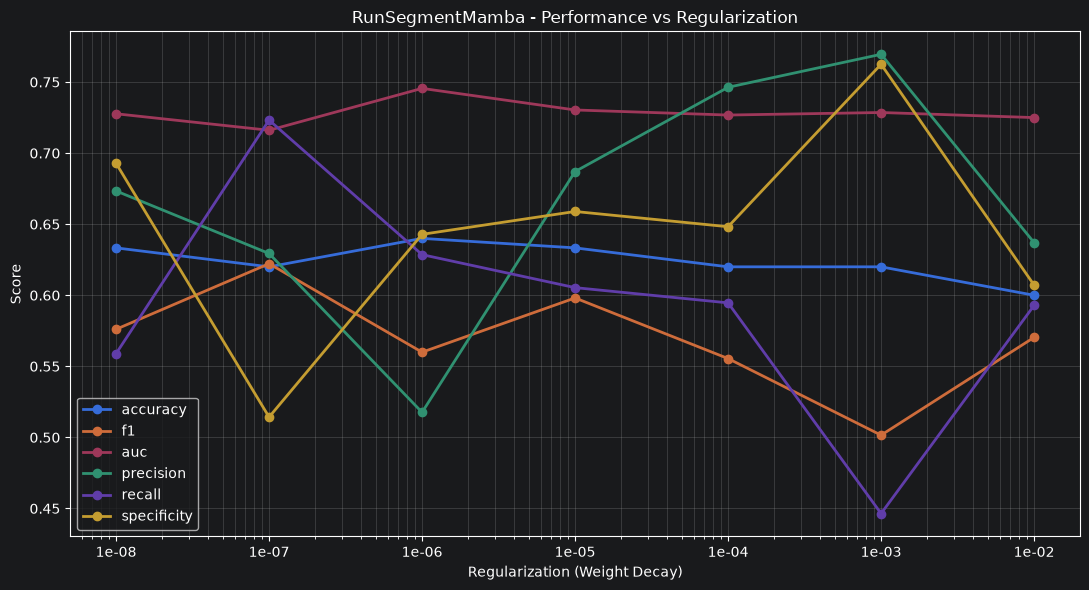


=== BEST REGULARIZATION ===
Regularization: 1.0e-06
Accuracy: 0.6400
F1: 0.5599
AUC: 0.7455
Precision: 0.5176
Recall: 0.6286
Specificity: 0.6429


In [5]:
# REGULARIZATION - RunSegmentMamba
import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

# Valori di weight decay da testare
regularization_values = [
    1e-8,
    1e-7,
    1e-6,
    1e-5,
    1e-4,
    1e-3,
    1e-2
]

# =========================================================
# EXPERIMENTS
# =========================================================

for reg in regularization_values:

    print(f"\n=== Running experiment with regularization={reg} ===")

    runner = RunSegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[4,8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative",),

        window_size=256,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=150,
        batch_size=32,
        learning_rate=1e-3,

        # REGOLARIZZAZIONE
        regularization=reg,

        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val no)/"
            f"regularization/reg_{reg}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "regularization": reg,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("regularization")

print("\n=== REGULARIZATION SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "segment_mamba_regularization_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["regularization"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xscale("log")

plt.xticks(
    regularization_values,
    [f"{x:.0e}" for x in regularization_values]
)

plt.xlabel("Regularization (Weight Decay)")
plt.ylabel("Score")
plt.title("RunSegmentMamba - Performance vs Regularization")

plt.grid(True, alpha=0.3, which="both")
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST REGULARIZATION ===")
print(f"Regularization: {best['regularization']:.1e}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")
print(f"Precision: {best['val_precision']:.4f}")
print(f"Recall: {best['val_recall']:.4f}")
print(f"Specificity: {best['val_specificity']:.4f}")


=== Running experiment with batch_size=8 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.8867 | train_accuracy=0.4667 | train_f1=0.3846 | train_auc=0.4683 | train_precision=0.4348 | train_recall=0.3448 | train_specificity=0.5806 | val_loss=0.6817 | val_accuracy=0.6333 | val_f1=0.7027 | val_auc=0.5580 | val_precision=0.6190 | val_recall=0.8125 | val_specificity=0.4286
Fold 01 | Epoch 02 | train_loss=0.7141 | train_accuracy=0.5167 | train_f1=0.4314 | train_auc=0.4961 | train_precision=0.5000 | train_recall=0.3793 | train_specificity=0.6452 | val_loss=0.6670 | val_accuracy=0.6333 | val_f1=0.7027 | val_auc=0.5357 | val_precision=0.6190 | val_recall=0.8125 | val_specificity=0.4286
Fold 01 | Epoch 03 | train_loss=0.6563 | train_accuracy=0.6167 | train_f1=0.6667 | train_auc=0.6819 | train_precision=0.5750 | train_recall=0.7931 | train_specificity=0.4516 | val_loss=0.6630 | val_accurac

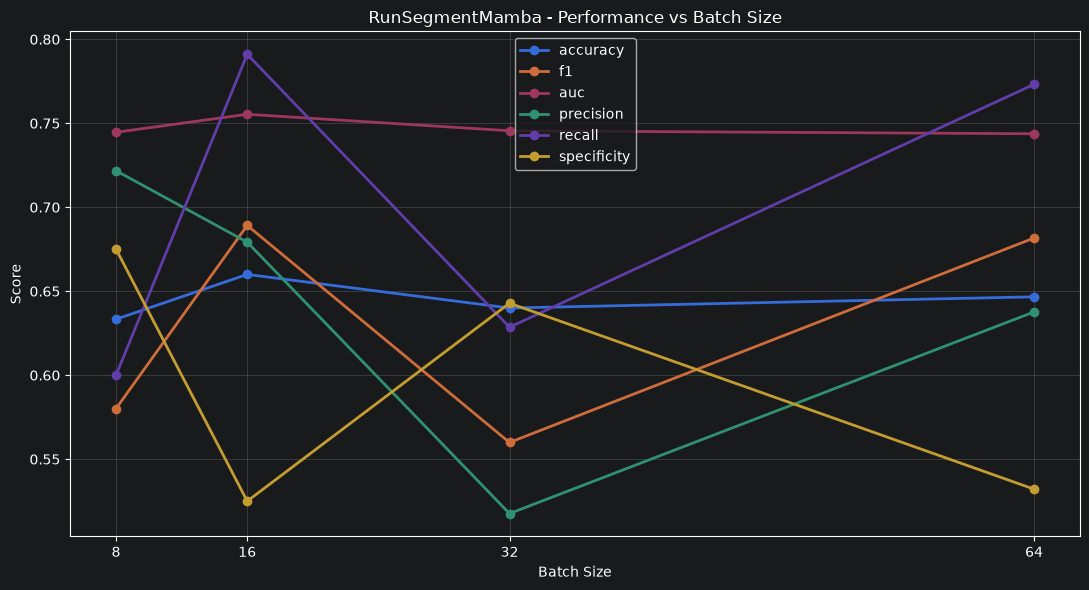


=== BEST BATCH SIZE ===
Batch Size: 16
Accuracy: 0.6600
F1: 0.6892
AUC: 0.7554
Precision: 0.6792
Recall: 0.7911
Specificity: 0.5250


In [6]:
# BATCH SIZE - RunFullySegmentMamba
import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

batch_sizes = [8, 16, 32, 64]

# =========================================================
# EXPERIMENTS
# =========================================================

for batch in batch_sizes:

    print(f"\n=== Running experiment with batch_size={batch} ===")

    runner = RunSegmentMamba(
        data_root=_project_path("PaHaW/PaHaW/PaHaW_public"),
        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================
        tasks=[4,8],
        feature_names=("x", "y"),
        engineered_features=("speed", "pressure_derivative",),

        window_size=256,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================
        epochs=150,
        batch_size=batch,
        learning_rate=1e-3,

        # REGOLARIZZAZIONE
        regularization=1e-6,

        n_splits=5,

        normalize=True,
        device="cuda" if torch.cuda.is_available() else "cpu",

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val no)/"
            f"batch_size/size_{batch}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            "monitor_metric": "auc",

            "early_stopping_patience": float("inf"),
            "min_delta": 0.0,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "batch_size": batch,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values("batch_size")

print("\n=== BATCH SIZE SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "segment_mamba_batch_size_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["batch_size"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(batch_sizes)

plt.xlabel("Batch Size")
plt.ylabel("Score")
plt.title("RunSegmentMamba - Performance vs Batch Size")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_accuracy",
    ascending=False
).iloc[0]

print("\n=== BEST BATCH SIZE ===")
print(f"Batch Size: {int(best['batch_size'])}")
print(f"Accuracy: {best['val_accuracy']:.4f}")
print(f"F1: {best['val_f1']:.4f}")
print(f"AUC: {best['val_auc']:.4f}")
print(f"Precision: {best['val_precision']:.4f}")
print(f"Recall: {best['val_recall']:.4f}")
print(f"Specificity: {best['val_specificity']:.4f}")


=== Running experiment with early_stopping_patience=20 ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7878 | train_accuracy=0.4500 | train_f1=0.5075 | train_auc=0.5250 | train_precision=0.4474 | train_recall=0.5862 | train_specificity=0.3226 | val_loss=0.6583 | val_accuracy=0.6333 | val_f1=0.7027 | val_auc=0.6830 | val_precision=0.6190 | val_recall=0.8125 | val_specificity=0.4286
Fold 01 | Epoch 02 | train_loss=0.8278 | train_accuracy=0.5000 | train_f1=0.2857 | train_auc=0.4694 | train_precision=0.4615 | train_recall=0.2069 | train_specificity=0.7742 | val_loss=0.7496 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.6518 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6863 | train_accuracy=0.5500 | train_f1=0.5091 | train_auc=0.6040 | train_precision=0.5385 | train_recall=0.4828 | train_specificity=0.6129 | val_loss=0.6733

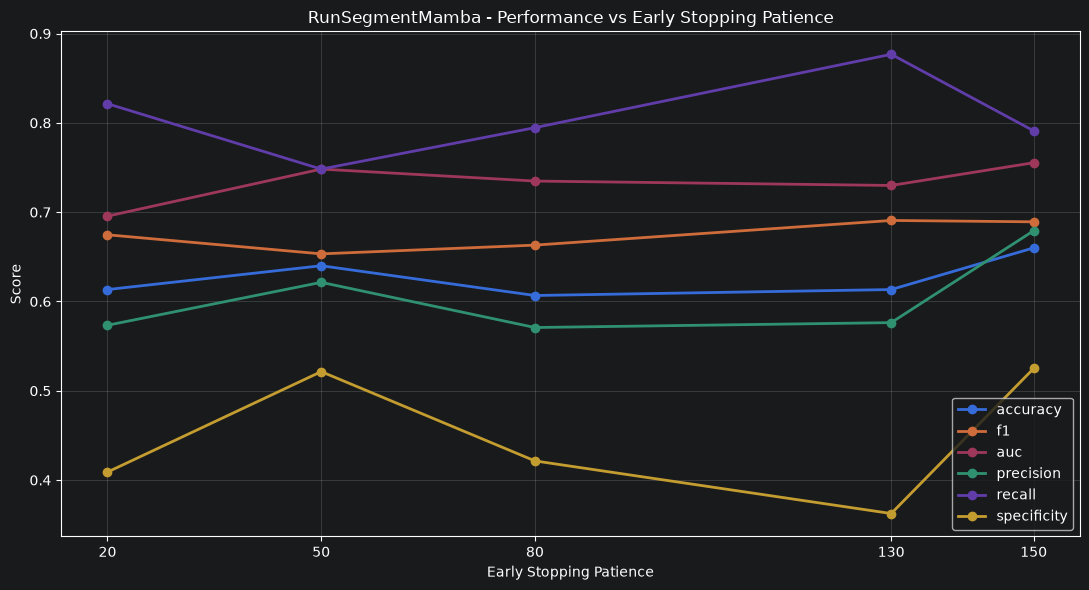


=== BEST EARLY STOPPING PATIENCE ===
Patience: 150
Accuracy: 0.6600
F1: 0.6892
AUC: 0.7554
Precision: 0.6792
Recall: 0.7911
Specificity: 0.5250


In [7]:
# EARLY STOPPING PATIENCE - RunSegmentMamba

import pandas as pd
import matplotlib.pyplot as plt
import torch

results = []

patience_values = [ 20, 50, 80, 130, 150]

# =========================================================
# EXPERIMENTS
# =========================================================

for patience in patience_values:

    print(
        f"\n=== Running experiment with "
        f"early_stopping_patience={patience} ==="
    )

    runner = RunSegmentMamba(
        data_root=_project_path(
            "PaHaW/PaHaW/PaHaW_public"
        ),

        metadata_path=_project_path(
            "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
        ),

        # =====================================================
        # Configurazione dati
        # =====================================================

        tasks=[4, 8],

        feature_names=("x", "y"),

        engineered_features=(
            "speed", "pressure_derivative"
        ),

        window_size=256,
        stride=None,
        include_last=True,

        # =====================================================
        # Training
        # =====================================================

        epochs=150,

        batch_size=16,

        learning_rate=1e-3,

        # REGOLARIZZAZIONE
        regularization=1e-6,

        n_splits=5,

        normalize=True,

        device=(
            "cuda"
            if torch.cuda.is_available()
            else "cpu"
        ),

        seed=42,

        output_dir=_project_path(
            f"experiments/test_iperparametri/"
            f"cnn_mamba(train seg - val no)/"
            f"early_stopping/patience_{patience}"
        ),

        training_cfg={
            "metrics": [
                "accuracy",
                "f1",
                "auc",
                "precision",
                "recall",
                "specificity",
            ],

            # Metrica monitorata
            "monitor_metric": "auc",

            # EARLY STOPPING
            "early_stopping_patience": patience,

            "min_delta": 1e-3,

            "results_writer": "csv",
            "save_metrics": True,
        },
    )

    summary = runner.run()

    row = {
        "early_stopping_patience": patience,
        "val_accuracy": summary["averages"]["val_accuracy"],
        "val_f1": summary["averages"]["val_f1"],
        "val_auc": summary["averages"]["val_auc"],
        "val_precision": summary["averages"]["val_precision"],
        "val_recall": summary["averages"]["val_recall"],
        "val_specificity": summary["averages"]["val_specificity"],
    }

    results.append(row)


# =========================================================
# DATAFRAME
# =========================================================

df = pd.DataFrame(results).sort_values(
    "early_stopping_patience"
)

print("\n=== EARLY STOPPING SUMMARY ===")
print(df)


# =========================================================
# SAVE
# =========================================================

df.to_csv(
    "segment_mamba_early_stopping_patience_summary.csv",
    index=False
)


# =========================================================
# PLOT
# =========================================================

metrics = [
    "val_accuracy",
    "val_f1",
    "val_auc",
    "val_precision",
    "val_recall",
    "val_specificity",
]

plt.figure(figsize=(11, 6))

for metric in metrics:

    plt.plot(
        df["early_stopping_patience"],
        df[metric],
        marker="o",
        linewidth=2,
        label=metric.replace("val_", "")
    )

plt.xticks(patience_values)

plt.xlabel("Early Stopping Patience")
plt.ylabel("Score")

plt.title(
    "RunSegmentMamba - Performance vs Early Stopping Patience"
)

plt.grid(
    True,
    alpha=0.3
)

plt.legend()

plt.tight_layout()

plt.show()


# =========================================================
# BEST CONFIGURATION
# =========================================================

best = df.sort_values(
    by="val_auc",
    ascending=False
).iloc[0]

print("\n=== BEST EARLY STOPPING PATIENCE ===")

print(
    f"Patience: "
    f"{int(best['early_stopping_patience'])}"
)

print(
    f"Accuracy: {best['val_accuracy']:.4f}"
)

print(
    f"F1: {best['val_f1']:.4f}"
)

print(
    f"AUC: {best['val_auc']:.4f}"
)

print(
    f"Precision: {best['val_precision']:.4f}"
)

print(
    f"Recall: {best['val_recall']:.4f}"
)

print(
    f"Specificity: {best['val_specificity']:.4f}"
)

In [9]:
# xy_speed_pressure_derivative - RunSegmentMamba

import pandas as pd
import matplotlib.pyplot as plt
import torch

# =========================================================
# CONFIGURATION
# =========================================================

print(
    f"\n=== Running experiment with "
    f"RunSegmentMamba -> xy_pressure_derivative ==="
)

runner = RunSegmentMamba(
    data_root=_project_path(
        "PaHaW/PaHaW/PaHaW_public"
    ),

    metadata_path=_project_path(
        "PaHaW/PaHaW/PaHaW_files/corpus_PaHaW.xlsx"
    ),

    # =====================================================
    # Configurazione dati
    # =====================================================

    tasks=[4, 8],

    feature_names=("x", "y"),

    engineered_features=(
        "speed", "pressure_derivative"
    ),

    window_size=256,
    stride=None,
    include_last=True,

    # =====================================================
    # Training
    # =====================================================

    epochs=150,

    batch_size=16,

    learning_rate=1e-3,

    # REGOLARIZZAZIONE
    regularization=1e-6,

    n_splits=5,

    normalize=True,

    device=(
        "cuda"
        if torch.cuda.is_available()
        else "cpu"
    ),

    seed=42,

    output_dir=_project_path(
        f"experiments/cnn1D + mamba/"
        f"raw_segment(train seg - val no)/"
        f"task_4_8/xy_speed_pressure_derivative"
    ),

    training_cfg={
        "metrics": [
            "accuracy",
            "f1",
            "auc",
            "precision",
            "recall",
            "specificity",
        ],

        # Metrica monitorata
        "monitor_metric": "auc",

        # EARLY STOPPING
        "early_stopping_patience": 150,

        "min_delta": 0.0,

        "results_writer": "csv",
        "save_metrics": True,
    },
)

# =========================================================
# RUN
# =========================================================

summary = runner.run()


# =========================================================
# RESULTS
# =========================================================

averages = summary["averages"]

print("\n=== FINAL RESULTS ===")

print(
    f"Patience:    {patience}"
)

print(
    f"Accuracy:    {averages['val_accuracy']:.4f}"
)

print(
    f"F1 Score:    {averages['val_f1']:.4f}"
)

print(
    f"AUC:         {averages['val_auc']:.4f}"
)

print(
    f"Precision:   {averages['val_precision']:.4f}"
)

print(
    f"Recall:      {averages['val_recall']:.4f}"
)

print(
    f"Specificity: {averages['val_specificity']:.4f}"
)


=== Running experiment with RunSegmentMamba -> xy_pressure_derivative ===

FOLD 01/5
Train patients: 60
Validation patients: 15
[WARNING] Mismatch in 00075__8_1.svc: expected 1663, found 1646.
Fold 01 | Epoch 01 | train_loss=0.7878 | train_accuracy=0.4500 | train_f1=0.5075 | train_auc=0.5250 | train_precision=0.4474 | train_recall=0.5862 | train_specificity=0.3226 | val_loss=0.6583 | val_accuracy=0.6333 | val_f1=0.7027 | val_auc=0.6830 | val_precision=0.6190 | val_recall=0.8125 | val_specificity=0.4286
Fold 01 | Epoch 02 | train_loss=0.8278 | train_accuracy=0.5000 | train_f1=0.2857 | train_auc=0.4694 | train_precision=0.4615 | train_recall=0.2069 | train_specificity=0.7742 | val_loss=0.7496 | val_accuracy=0.4667 | val_f1=0.0000 | val_auc=0.6518 | val_precision=0.0000 | val_recall=0.0000 | val_specificity=1.0000
Fold 01 | Epoch 03 | train_loss=0.6863 | train_accuracy=0.5500 | train_f1=0.5091 | train_auc=0.6040 | train_precision=0.5385 | train_recall=0.4828 | train_specificity=0.6129 | 